# A guide Portfolio Optimization Environment

This notebook aims to provide an example of using PortfolioOptimizationEnv (or POE) to train a reinforcement learning model that learns to solve the portfolio optimization problem.

In this document, we will reproduce a famous architecture called EIIE (ensemble of identical independent evaluators), introduced in the following paper:

- Zhengyao Jiang, Dixing Xu, & Jinjun Liang. (2017). A Deep Reinforcement Learning Framework for the Financial Portfolio Management Problem. https://doi.org/10.48550/arXiv.1706.10059.

It's advisable to read it to understand the algorithm implemented in this notebook.

### Note
If you're using this environment, consider citing the following paper (in adittion to FinRL references):

- Caio Costa, & Anna Costa (2023). POE: A General Portfolio Optimization Environment for FinRL. In *Anais do II Brazilian Workshop on Artificial Intelligence in Finance* (pp. 132–143). SBC. https://doi.org/10.5753/bwaif.2023.231144.

```
@inproceedings{bwaif,
 author = {Caio Costa and Anna Costa},
 title = {POE: A General Portfolio Optimization Environment for FinRL},
 booktitle = {Anais do II Brazilian Workshop on Artificial Intelligence in Finance},
 location = {João Pessoa/PB},
 year = {2023},
 keywords = {},
 issn = {0000-0000},
 pages = {132--143},
 publisher = {SBC},
 address = {Porto Alegre, RS, Brasil},
 doi = {10.5753/bwaif.2023.231144},
 url = {https://sol.sbc.org.br/index.php/bwaif/article/view/24959}
}

```

## Installation and imports

To run this notebook in google colab, uncomment the cells below.

In [ ]:
## install finrl library
# !sudo apt install swig
# !pip install git+https://github.com/AI4Finance-Foundation/FinRL.git

In [ ]:
## We also need to install quantstats, because the environment uses it to plot graphs
# !pip install quantstats

In [52]:
## Hide matplotlib warnings
# import warnings
# warnings.filterwarnings('ignore')

import logging
logging.getLogger('matplotlib.font_manager').disabled = True

#### Import the necessary code libraries

In [54]:
import torch

from sklearn.preprocessing import MaxAbsScaler

from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import GroupByScaler
from finrl.meta.env_portfolio_optimization.env_portfolio_optimization import PortfolioOptimizationEnv
from finrl.agents.portfolio_optimization.models import DRLAgent
from finrl.agents.portfolio_optimization.architectures_raw import EIIE

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

## Fetch data

In his paper, *Jiang et al* creates a portfolio composed by the top-11 cryptocurrencies based on 30-days volume. Since it's not specified when this classification was done, it's difficult to reproduce, so we will use a similar approach in the Brazillian stock market:

- We select top-10 stocks from Brazillian stock market;
- For simplicity, we disconsider stocks that have missing data for the days in period 2011-01-01 to 2019-12-31 (9 years);

In [55]:
TOP_BRL = [
    "VALE3.SA", "PETR4.SA", "ITUB4.SA", "BBDC4.SA",
    "BBAS3.SA", "RENT3.SA", "LREN3.SA", "PRIO3.SA",
    "WEGE3.SA", "ABEV3.SA"
]

In [ ]:
# TOP_BRL = [
#         "601012.SS",
#         "600887.SS",
#         "600030.SS",   
#         "600031.SS",
#         "600036.SS",        
#         "600276.SS", 
#         "600519.SS", 
#         "601318.SS", 
#         "600703.SS", 
#         "601166.SS", 
#     ]

In [56]:
%env HTTP_PROXY=http://127.0.0.1:7897
%env HTTPS_PROXY=http://127.0.0.1:7897

env: HTTP_PROXY=http://127.0.0.1:7897
env: HTTPS_PROXY=http://127.0.0.1:7897


In [71]:
print(len(TOP_BRL))

portfolio_raw_df = YahooDownloader(start_date = '2011-01-01',
                                end_date = '2022-12-31',
                                ticker_list = TOP_BRL).fetch_data()
portfolio_raw_df

10


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Shape of DataFrame:  (29780, 8)


Price,date,close,high,low,open,volume,tic,day
0,2011-01-03,4.293334,4.312087,4.263725,4.264712,576145,ABEV3.SA,0
1,2011-01-03,5.564075,5.634955,5.560531,5.581796,6626800,BBAS3.SA,0
2,2011-01-03,5.545339,5.617509,5.521842,5.562123,10862336,BBDC4.SA,0
3,2011-01-03,7.239846,7.312829,7.197882,7.225250,11346613,ITUB4.SA,0
4,2011-01-03,5.218464,5.291590,5.164534,5.164534,4017796,LREN3.SA,0
...,...,...,...,...,...,...,...,...
29775,2022-12-29,13.865266,14.176526,13.825651,14.142571,57901800,PETR4.SA,3
29776,2022-12-29,37.150330,37.419897,36.561276,37.190266,7890300,PRIO3.SA,3
29777,2022-12-29,46.712036,49.135441,46.360817,47.835935,8786791,RENT3.SA,3
29778,2022-12-29,66.229431,67.026747,66.192177,66.318852,40110800,VALE3.SA,3


In [72]:
portfolio_raw_df.groupby("tic").count()

Price,date,close,high,low,open,volume,day
tic,,,,,,,
ABEV3.SA,2978,2978,2978,2978,2978,2978,2978
BBAS3.SA,2978,2978,2978,2978,2978,2978,2978
BBDC4.SA,2978,2978,2978,2978,2978,2978,2978
ITUB4.SA,2978,2978,2978,2978,2978,2978,2978
LREN3.SA,2978,2978,2978,2978,2978,2978,2978
PETR4.SA,2978,2978,2978,2978,2978,2978,2978
PRIO3.SA,2978,2978,2978,2978,2978,2978,2978
RENT3.SA,2978,2978,2978,2978,2978,2978,2978
VALE3.SA,2978,2978,2978,2978,2978,2978,2978


### Normalize Data

We normalize the data dividing the time series of each stock by its maximum value, so that the dataframe contains values between 0 and 1.

In [73]:
portfolio_norm_df = GroupByScaler(by="tic", scaler=MaxAbsScaler).fit_transform(portfolio_raw_df)
portfolio_norm_df

c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00200262 0.00114137 0.0010422  ... 0.04565734 0.05214546 0.07760399]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(
c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.   0.25 0.5  ... 0.25 0.5  0.75]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(


Price,date,close,high,low,open,volume,tic,day
0,2011-01-03,0.266099,0.264105,0.266903,0.263024,0.002003,ABEV3.SA,0.00
1,2011-01-03,0.321735,0.323948,0.326813,0.323461,0.014581,BBAS3.SA,0.00
2,2011-01-03,0.292122,0.291998,0.293792,0.291601,0.021760,BBDC4.SA,0.00
3,2011-01-03,0.312010,0.313424,0.315005,0.315202,0.062331,ITUB4.SA,0.00
4,2011-01-03,0.128688,0.130427,0.129054,0.127421,0.072591,LREN3.SA,0.00
...,...,...,...,...,...,...,...,...
29775,2022-12-29,0.694899,0.698099,0.718239,0.732488,0.082841,PETR4.SA,0.75
29776,2022-12-29,0.857373,0.844144,0.878173,0.858295,0.048724,PRIO3.SA,0.75
29777,2022-12-29,0.728877,0.759975,0.732256,0.747023,0.097191,RENT3.SA,0.75
29778,2022-12-29,0.916710,0.920399,0.932491,0.911700,0.218546,VALE3.SA,0.75


In [74]:
df_portfolio = portfolio_norm_df[["date", "tic", "close", "high", "low"]]

df_portfolio_train = df_portfolio[(df_portfolio["date"] >= "2011-01-01") & (df_portfolio["date"] < "2019-12-31")]
df_portfolio_2020 = df_portfolio[(df_portfolio["date"] >= "2020-01-01") & (df_portfolio["date"] < "2020-12-31")]
df_portfolio_2021 = df_portfolio[(df_portfolio["date"] >= "2021-01-01") & (df_portfolio["date"] < "2021-12-31")]
df_portfolio_2022 = df_portfolio[(df_portfolio["date"] >= "2022-01-01") & (df_portfolio["date"] < "2022-12-31")]

In [75]:
df_portfolio_train

Price,date,tic,close,high,low
0,2011-01-03,ABEV3.SA,0.266099,0.264105,0.266903
1,2011-01-03,BBAS3.SA,0.321735,0.323948,0.326813
2,2011-01-03,BBDC4.SA,0.292122,0.291998,0.293792
3,2011-01-03,ITUB4.SA,0.312010,0.313424,0.315005
4,2011-01-03,LREN3.SA,0.128688,0.130427,0.129054
...,...,...,...,...,...
22325,2019-12-30,PETR4.SA,0.434359,0.434273,0.449787
22326,2019-12-30,PRIO3.SA,0.152350,0.153874,0.157553
22327,2019-12-30,RENT3.SA,0.623973,0.629988,0.630149
22328,2019-12-30,VALE3.SA,0.409274,0.410299,0.415772


### Instantiate Environment

Using the `PortfolioOptimizationEnv`, it's easy to instantiate a portfolio optimization environment for reinforcement learning agents. In the example below, we use the dataframe created before to start an environment.

In [76]:
environment = PortfolioOptimizationEnv(
        df_portfolio_train,
        initial_amount=100000,
        comission_fee_pct=0.0025,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
    )

### Instantiate Model

Now, we can instantiate the model using FinRL API. In this example, we are going to use the EIIE architecture introduced by Jiang et. al.

:exclamation: **Note:** Remember to set the architecture's `time_window` parameter with the same value of the environment's `time_window`.

In [77]:
# set PolicyGradient parameters
model_kwargs = {
    "lr": 0.01,
    "policy": EIIE,
}

# here, we can set EIIE's parameters
policy_kwargs = {
    "k_size": 3,
    "time_window": 50,
}

model = DRLAgent(environment).get_model("pg", device, model_kwargs, policy_kwargs)

### Train Model

In [ ]:
DRLAgent.train_model(model, episodes=10)

  0%|          | 0/10 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 359901.8125
Final accumulative portfolio value: 3.599018125
Maximum DrawDown: -0.4441885811262146
Sharpe ratio: 0.7809714537709873


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 10%|█         | 1/10 [00:35<05:15, 35.01s/it]

Initial portfolio value:100000
Final portfolio value: 359903.46875
Final accumulative portfolio value: 3.5990346875
Maximum DrawDown: -0.44418479851208925
Sharpe ratio: 0.7809763617430142


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 20%|██        | 2/10 [01:09<04:38, 34.87s/it]

...

c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 40%|████      | 4/10 [02:20<03:32, 35.36s/it]

Initial portfolio value:100000
Final portfolio value: 359883.6875
Final accumulative portfolio value: 3.598836875
Maximum DrawDown: -0.44418225637875175
Sharpe ratio: 0.7809446758311919


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 50%|█████     | 5/10 [02:55<02:56, 35.34s/it]

Initial portfolio value:100000
Final portfolio value: 359891.03125
Final accumulative portfolio value: 3.5989103125
Maximum DrawDown: -0.4441824084451568
Sharpe ratio: 0.7809577394788331


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)
 60%|██████    | 6/10 [03:31<02:21, 35.32s/it]

### Save Model

In [79]:
torch.save(model.train_policy.state_dict(), "policy_EIIE.pt")

## Test Model

### Instantiate different environments

Since we have three different periods of time, we need three different environments instantiated to simulate them.

In [80]:
env_eiie_2022 = PortfolioOptimizationEnv(
    df_portfolio_2020,
    initial_amount=100000,
    comission_fee_pct=0.0025,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

env_eiie_2023 = PortfolioOptimizationEnv(
    df_portfolio_2021,
    initial_amount=100000,
    comission_fee_pct=0.0025,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

env_eiie_2024 = PortfolioOptimizationEnv(
    df_portfolio_2022,
    initial_amount=100000,
    comission_fee_pct=0.0025,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

### Test EIIE/EI3 architecture
Now, we can test the EIIE architecture in the three different test periods. It's important no note that, in this code, we load the saved policy even though it's not necessary just to show how to save and load your model.

In [81]:
import numpy as np
EIIE_results = {
    "training": environment._asset_memory["final"],
    "2022": {},
    "2023": {},
    "2024": {}
}

# instantiate an architecture with the same arguments used in training
# and load with load_state_dict.
policy = EIIE(time_window=50, device=device)

policy.load_state_dict(torch.load("policy_EIIE.pt"))

# 2022
DRLAgent.DRL_validation(model, env_eiie_2022, policy=policy)
EIIE_results["2022"] = {
    "value": list(env_eiie_2022._asset_memory["final"]),
    "actions": np.array(env_eiie_2022._actions_memory).copy(),
}
# 2023
DRLAgent.DRL_validation(model, env_eiie_2023, policy=policy)
EIIE_results["2023"] = {
    "value": list(env_eiie_2023._asset_memory["final"]),
    "actions": np.array(env_eiie_2023._actions_memory).copy(),
}

# 2024
DRLAgent.DRL_validation(model, env_eiie_2024, policy=policy)
EIIE_results["2024"] = {
    "value": list(env_eiie_2024._asset_memory["final"]),
    "actions": np.array(env_eiie_2024._actions_memory).copy(),
}

C:\Users\64954\AppData\Local\Temp\ipykernel_5172\3639105586.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load("policy_EIIE.pt"))


Initial portfolio value:100000
Final portfolio value: 164040.09375
Final accumulative portfolio value: 1.6404009375
Maximum DrawDown: -0.22926531250000004
Sharpe ratio: 1.7093315952123302


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 96235.3984375
Final accumulative portfolio value: 0.962353984375
Maximum DrawDown: -0.15763604837199074
Sharpe ratio: -0.15638295540456204


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 112806.7734375
Final accumulative portfolio value: 1.128067734375
Maximum DrawDown: -0.15213730954780358
Sharpe ratio: 0.8331426781380672


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


### Test Uniform Equal Weight
For comparison, we will also test the performance of a uniform Equal Weight strategy. In this strategy, the portfolio has no remaining cash and the same percentage of money is allocated in each asset.

In [38]:
EW_results = {
    "train": {},
    "2022": {},
    "2023": {},
    "2024": {}
}

PORTFOLIO_SIZE = len(TOP_BRL)

# train period
terminated = False
environment.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment.step(action)
EW_results["train"]["value"] = environment._asset_memory["final"]

# 2022
terminated = False
env_eiie_2022.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = env_eiie_2022.step(action)
EW_results["2022"]["value"] = env_eiie_2022._asset_memory["final"]

# 2023
terminated = False
env_eiie_2023.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = env_eiie_2023.step(action)
EW_results["2023"]["value"] = env_eiie_2023._asset_memory["final"]

# 2024
terminated = False
env_eiie_2024.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = env_eiie_2024.step(action)
EW_results["2024"]["value"] = env_eiie_2024._asset_memory["final"]

Initial portfolio value:100000
Final portfolio value: 573377.1875
Final accumulative portfolio value: 5.733771875
Maximum DrawDown: -0.4809339586471013
Sharpe ratio: 0.9072271706163714


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 114112.3125
Final accumulative portfolio value: 1.141123125
Maximum DrawDown: -0.16595133415745922
Sharpe ratio: 0.8415560395975433


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 129062.671875
Final accumulative portfolio value: 1.29062671875
Maximum DrawDown: -0.1056091559214708
Sharpe ratio: 1.9509868685342822


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 94341.1875
Final accumulative portfolio value: 0.943411875
Maximum DrawDown: -0.12687294311389452
Sharpe ratio: -0.4284929942678143


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Arial.
  _plt.savefig(savefig)


### Plot graphics

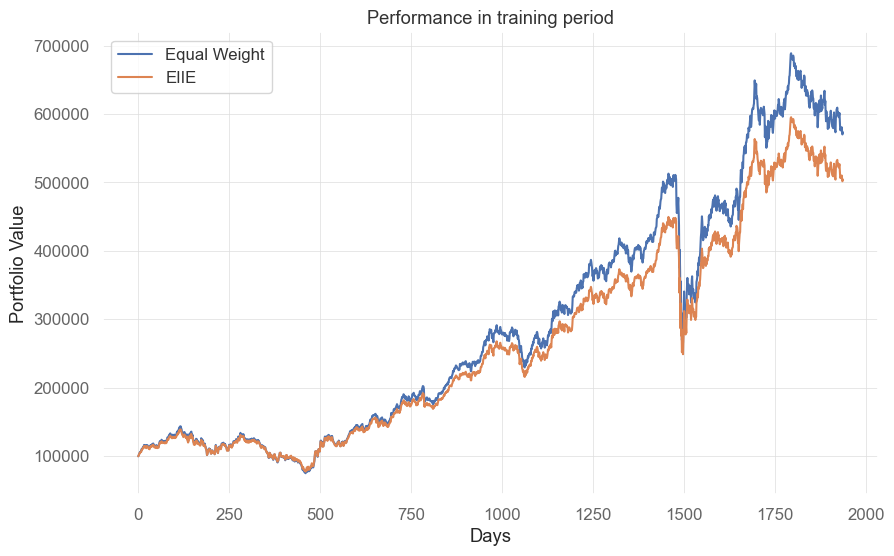

In [39]:
import matplotlib.pyplot as plt
%matplotlib inline 

plt.plot(EW_results["train"]["value"], label="Equal Weight")
plt.plot(EIIE_results["training"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in training period")
plt.legend()

plt.show()

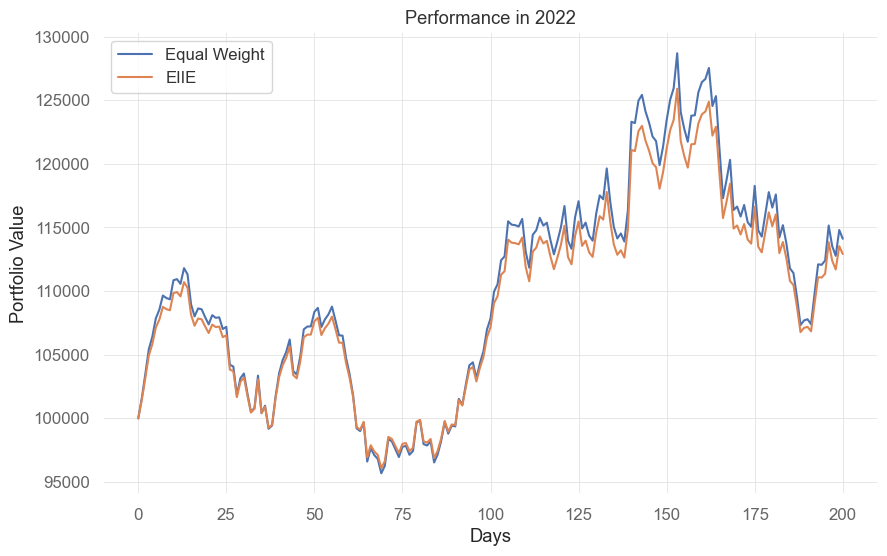

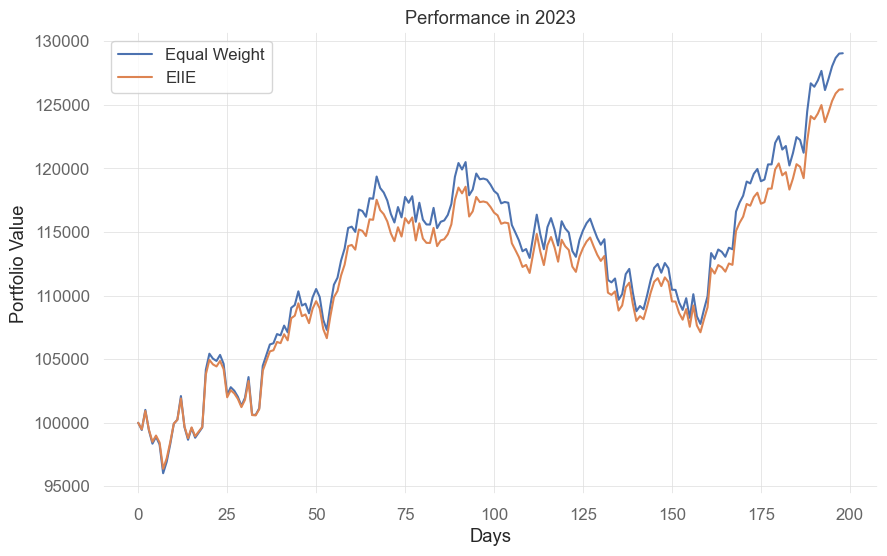

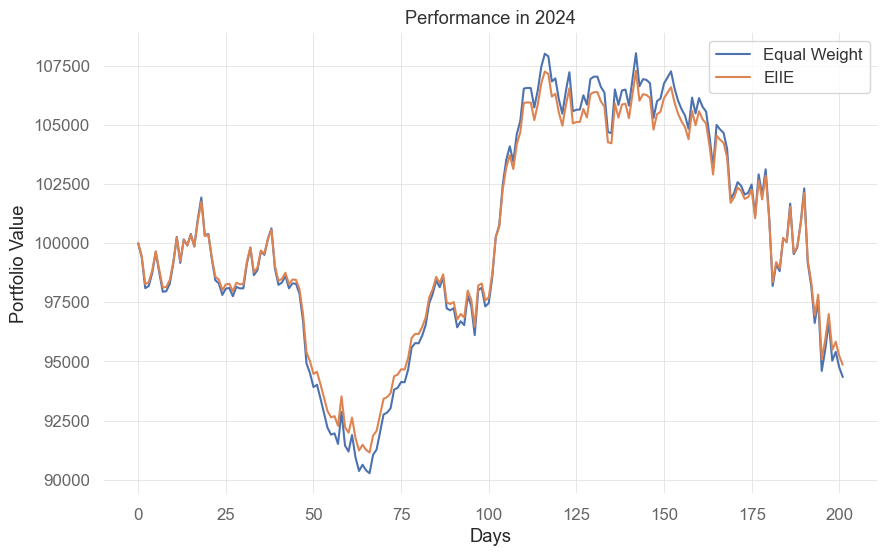

In [40]:
plt.plot(EW_results["2022"]["value"], label="Equal Weight")
plt.plot(EIIE_results["2022"]["value"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in 2022")
plt.legend()

plt.show()

plt.plot(EW_results["2023"]["value"], label="Equal Weight")
plt.plot(EIIE_results["2023"]["value"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in 2023")
plt.legend()

plt.show()

plt.plot(EW_results["2024"]["value"], label="Equal Weight")
plt.plot(EIIE_results["2024"]["value"], label="EIIE")

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Performance in 2024")
plt.legend()

plt.show()

We can see that the agent is able to learn a good policy but its performance is worse the more the test period advances into the future. To get a better performance in 2022, for example, the agent should probably be trained again using more recent data.

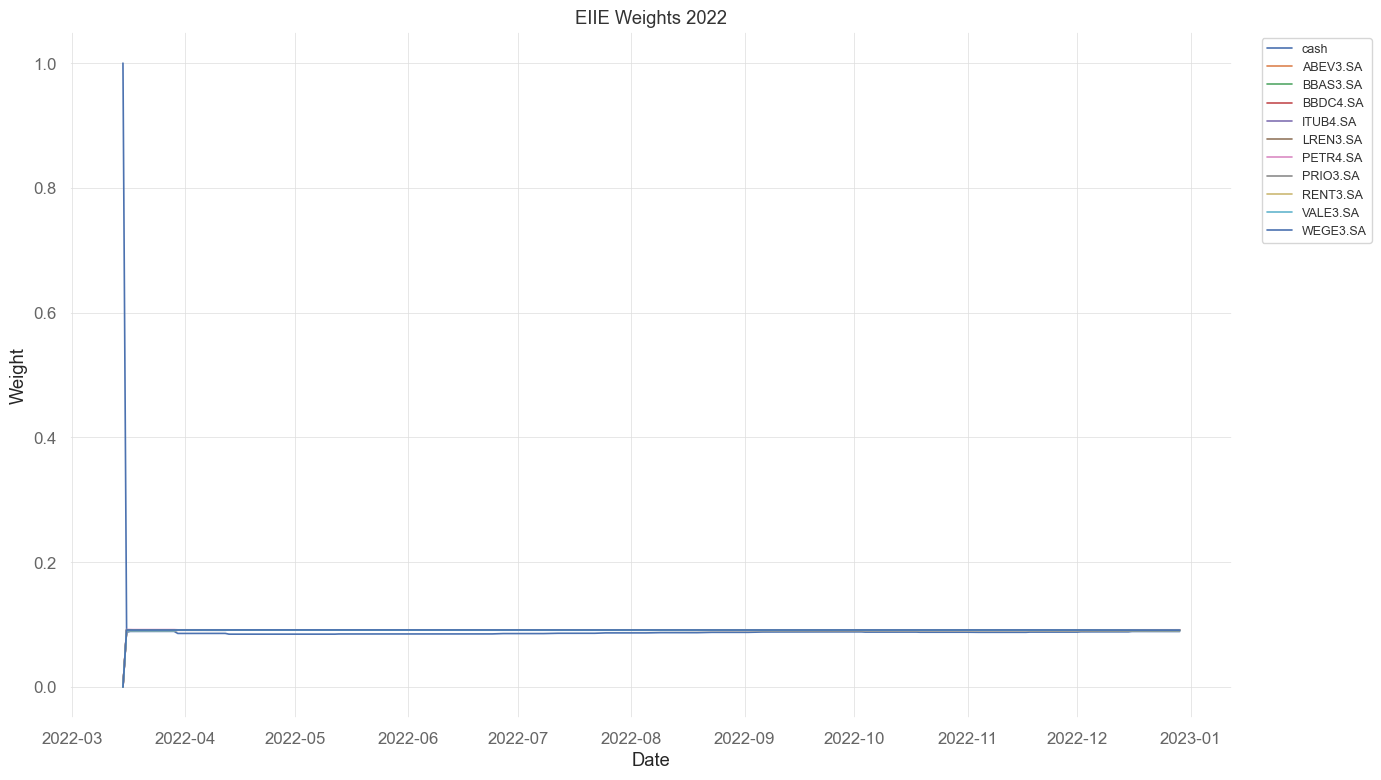

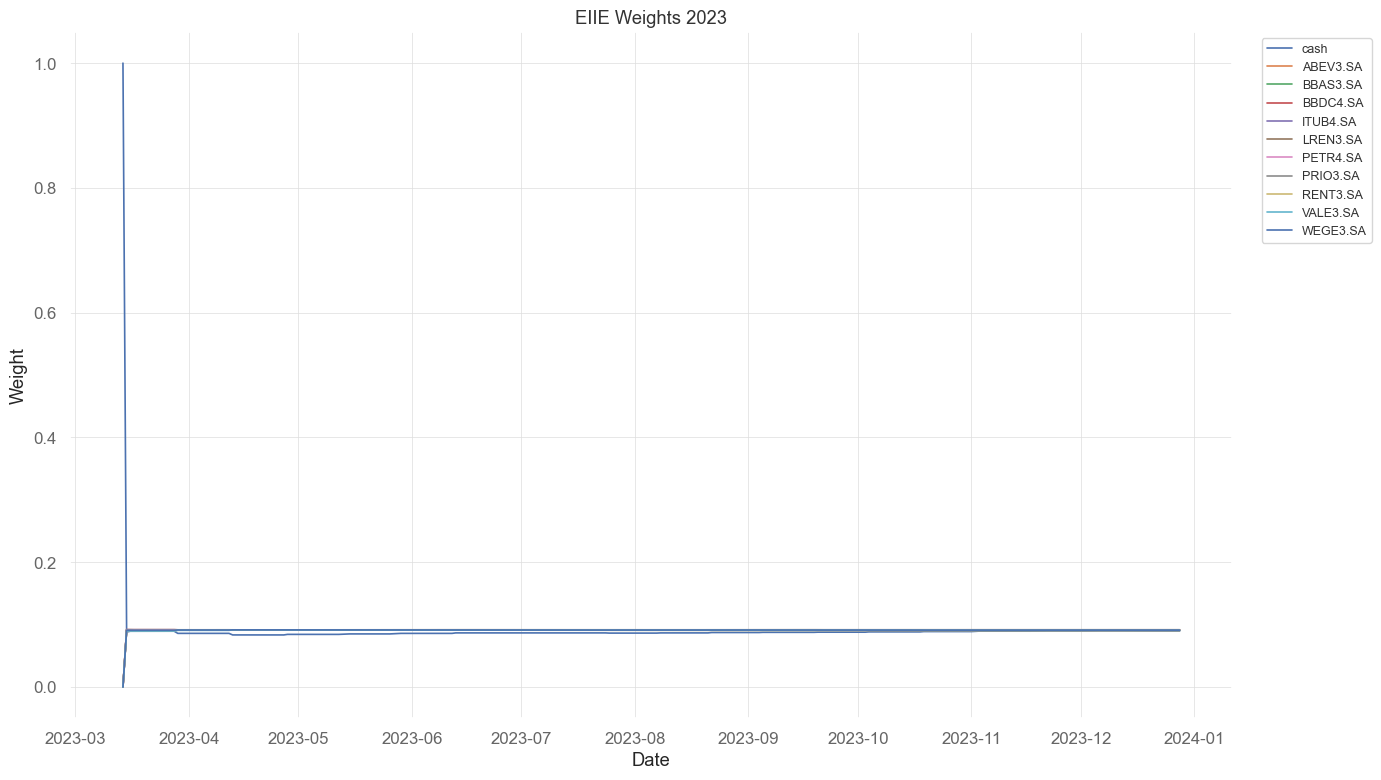

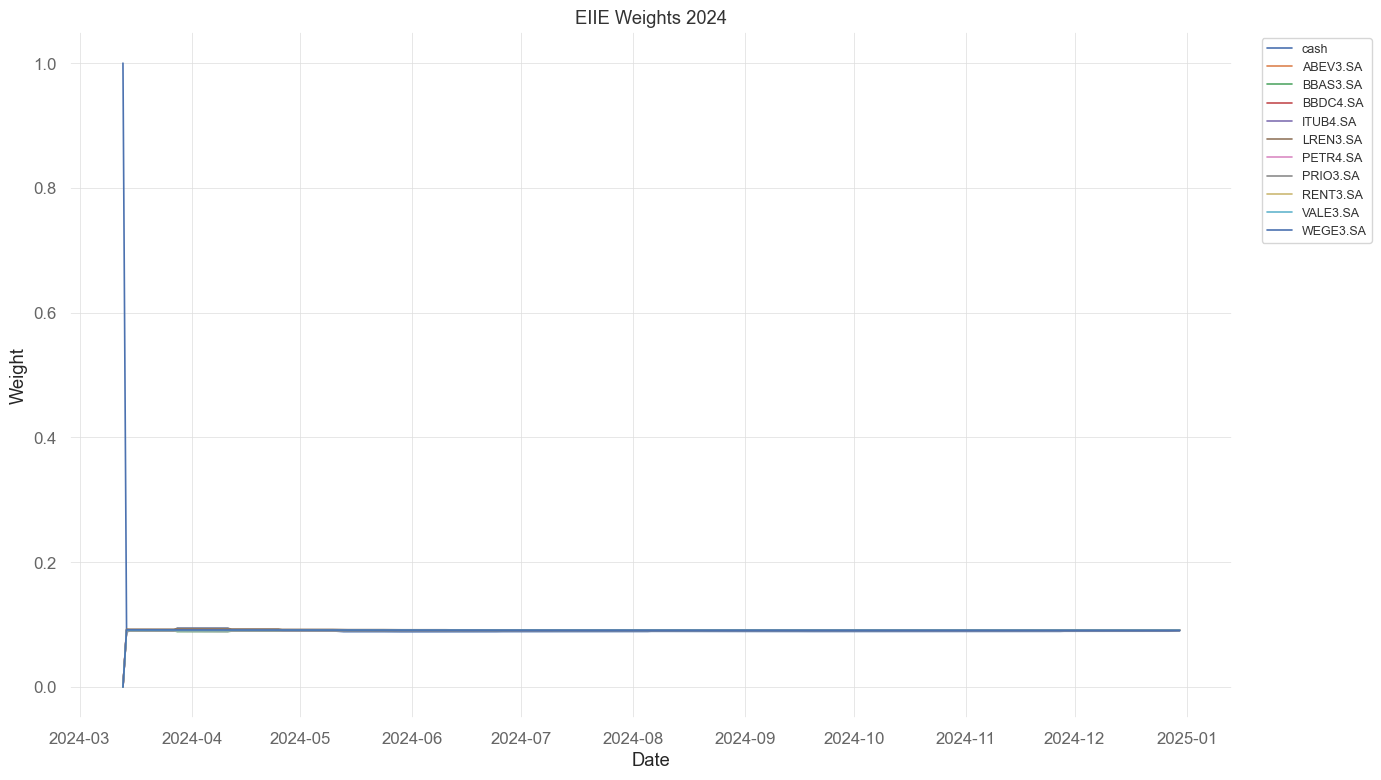

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_actions(actions, raw_df, title, save_path=None):
    actions = np.asarray(actions, dtype=np.float32)

    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = dates[-n_steps:] if len(dates) >= n_steps else np.arange(n_steps)

    tics = sorted(raw_df["tic"].unique().tolist())
    labels = ["cash"] + tics if actions.shape[1] == len(tics) + 1 else [f"asset_{i}" for i in range(actions.shape[1])]

    plt.figure(figsize=(14, 8))
    for i in range(actions.shape[1]):
        plt.plot(x_dates, actions[:, i], linewidth=1.2, label=labels[i])

    plt.xlabel("Date")
    plt.ylabel("Weight")
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

plot_actions(EIIE_results["2022"]["actions"], df_portfolio_2022, "EIIE Weights 2022")
plot_actions(EIIE_results["2023"]["actions"], df_portfolio_2023, "EIIE Weights 2023")
plot_actions(EIIE_results["2024"]["actions"], df_portfolio_2024, "EIIE Weights 2024")
